# Data Preprocessing: Mathematical Feature Transformations

## Project Overview
This notebook focuses on **Feature Engineering** techniques specifically aimed at handling non-normal distributions and skewed numerical data. Many machine learning algorithms (such as **Logistic Regression** and Linear Models) assume or perform significantly better when numerical input features follow a Gaussian (normal) distribution. 

We utilize Scikit-Learn's `ColumnTransformer` and `FunctionTransformer` to apply, evaluate, and compare various mathematical transformations to see which one optimizes model accuracy and cleans up feature distributions.

---

## 🛠️ Transformations Implemented & Evaluated
We evaluate four core mathematical transformations on our continuous features (e.g., `Fare`, `Age`):

*   **Log Transformation (`np.log1p`):** Shrinks right-skewed data distributions and handles heavy outliers by compressing the upper tail.
*   **Reciprocal Transformation (`1 / X`):** Inverts the values, drastically changing the scale; highly effective for specific ratios but sensitive to zero values.
*   **Square Transformation (`X ** 2`):** Accents larger values; typically utilized for left-skewed distributions.
*   **Square Root Transformation (`np.sqrt`):** Moderately reduces right-skewness; milder than a log transform and works naturally with zero values.

---

## 📊 Evaluation Metrics & Visualizations
To determine the best transformation strategy, every function run executes a dual-validation process:
1. **Statistical Verification:** We calculate and track model performance gains using a **10-Fold Cross-Validation Accuracy Score** via a `LogisticRegression` baseline.
2. **Visual Verification:** We construct side-by-side plots consisting of a **Probability Density Function (Histogram + KDE)** and a **Quantile-Quantile (Q-Q) Plot** to assess normality before and after the transformation.


In [1]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer


In [10]:
df = pd.read_csv('train.csv', usecols=['Age', 'Fare', 'Survived'])

In [11]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [22]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Age'] = df['Age'].round().astype('Int64')

In [26]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [24]:
df.sample(5)

,Survived,Age,Fare
741,0,36,78.8500
701,1,35,26.2875
773,0,30,7.2250
629,0,30,7.7333
806,0,39,0.0000


In [27]:
x = df.iloc[:,1:3]
y = df.iloc[:,0]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state=42)

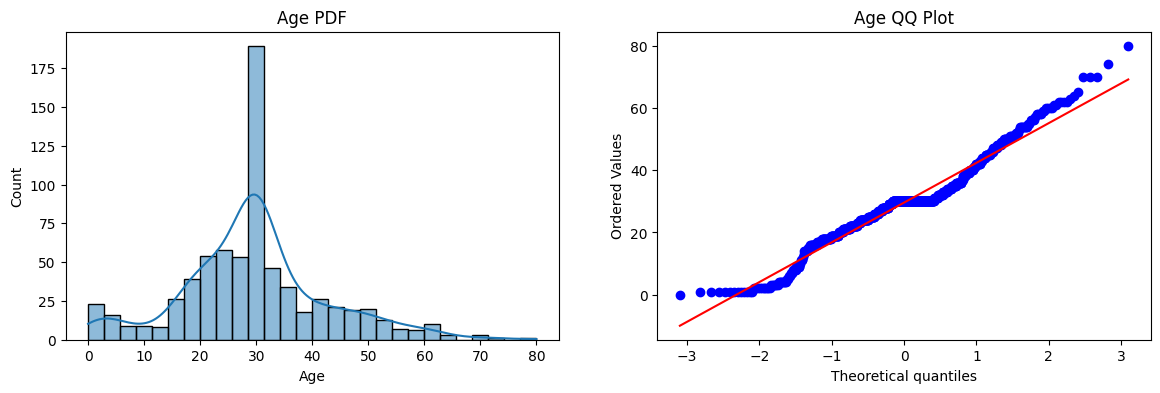

In [33]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train['Age'], kde=True)
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

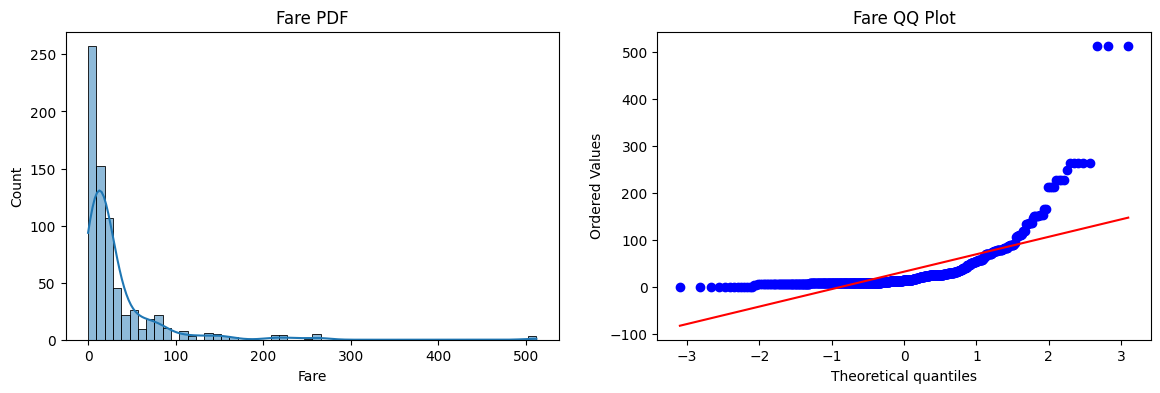

In [34]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train['Fare'], kde=True)
plt.title('Fare PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare QQ Plot')

plt.show()

In [36]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [37]:
clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)

print("Accuracy LR", accuracy_score(y_test,y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.659217877094972


In [38]:
trf = FunctionTransformer(func=np.log1p)

In [39]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [41]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed, y_train)

y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)

print("Accuracy LR", accuracy_score(y_test,y_pred))
print("Accuracy DT", accuracy_score(y_test,y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.659217877094972


In [43]:
X_transformed = trf.fit_transform(x)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR", np.mean(cross_val_score(clf, X_transformed, y, scoring='accuracy', cv=10)))
print("DT", np.mean(cross_val_score(clf2, X_transformed, y, scoring='accuracy', cv=10)))

LR 0.678027465667915
DT 0.6588514357053683


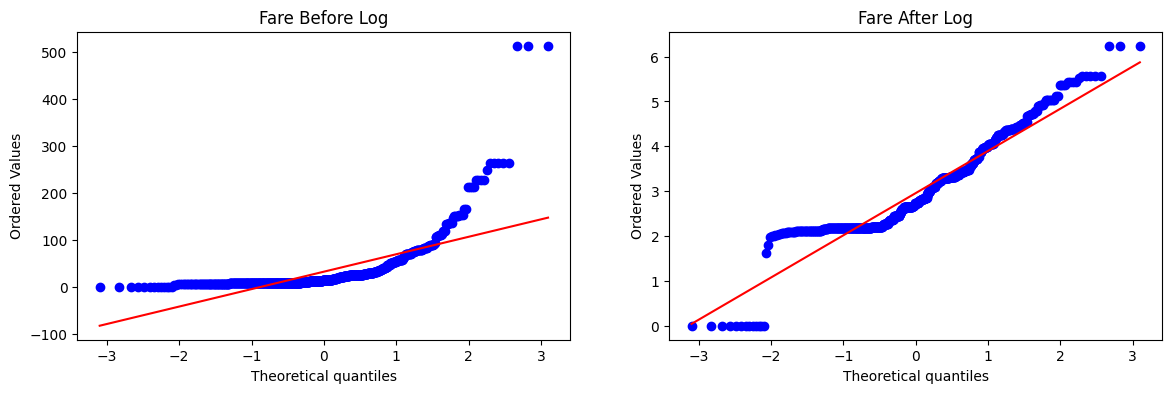

In [46]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()

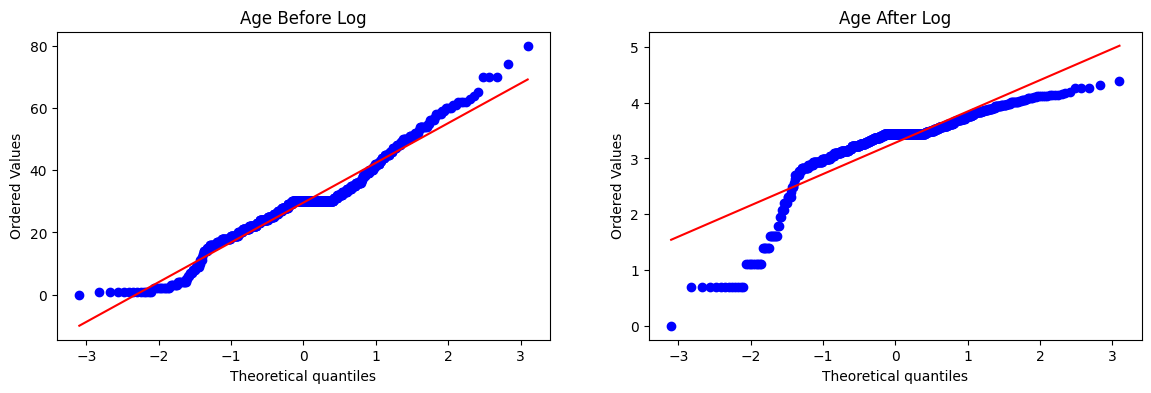

In [47]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Age After Log')

plt.show()

In [51]:
trf2 = ColumnTransformer([('log', FunctionTransformer(func=np.log1p), ['Fare'])], remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [52]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2, y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred1 = clf2.predict(X_test_transformed2)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred1))

Accuracy LR 0.6703910614525139
Accuracy DT 0.6815642458100558


In [53]:
X_transformed2 = trf2.fit_transform(x)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR", np.mean(cross_val_score(clf, X_transformed2, y, scoring='accuracy', cv=10)))
print("DT", np.mean(cross_val_score(clf2, X_transformed2, y, scoring='accuracy', cv=10)))

LR 0.6712609238451936
DT 0.6599875156054933


In [54]:
def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))
    
    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')
    
    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')
    
    plt.show()


Accuracy 0.616167290886392


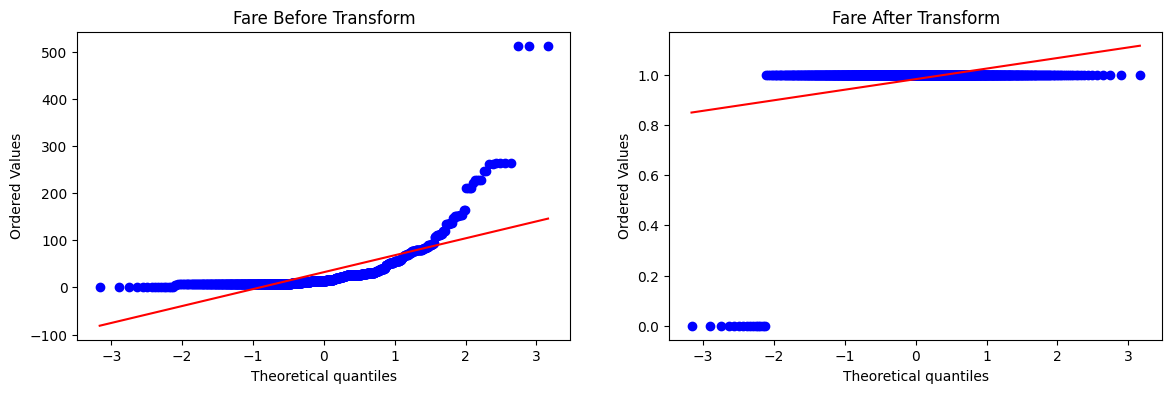

In [59]:
apply_transform(lambda x: x**1/(x+.01))